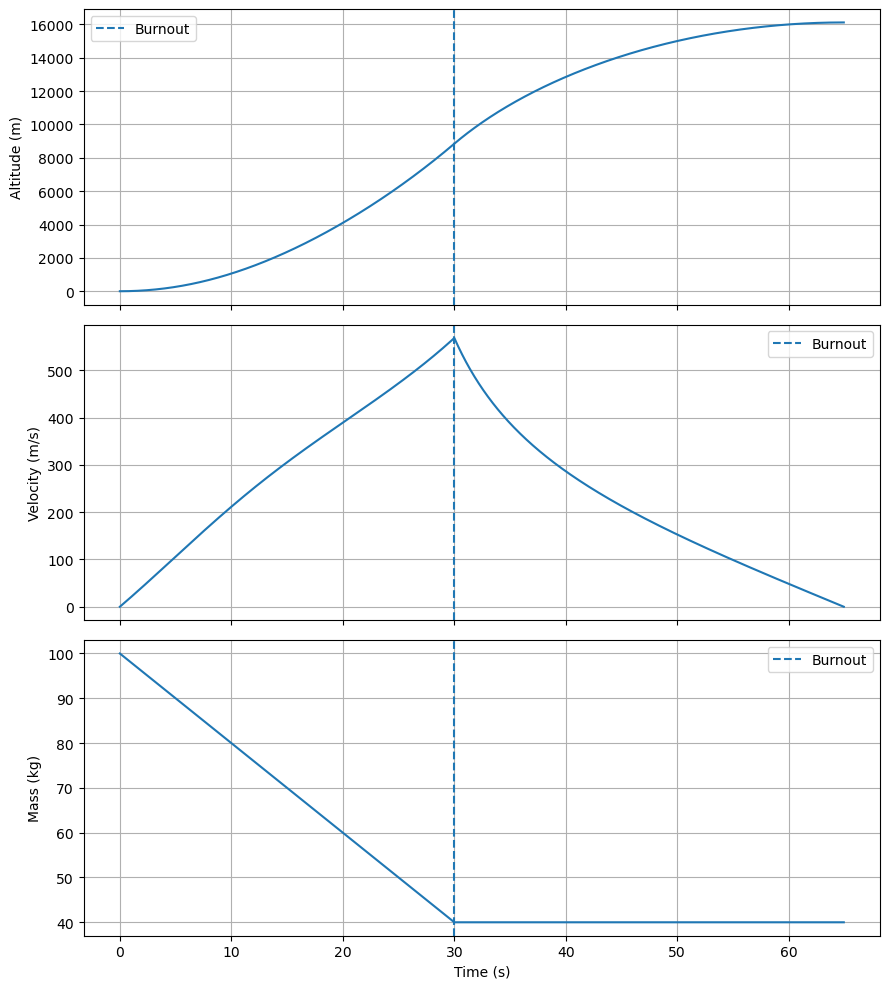

Burnout time: 30.00 s
Maximum altitude: 16.115 km
Time to apogee: 64.933 s


In [1]:

import numpy as np
import matplotlib.pyplot as plt

# Baseline parameters
m0 = 100.0
md = 40.0
T0 = 3000.0
mdot = 2.0
Cd = 0.5
A = 0.05
rho0 = 1.225
H = 8500.0
g0 = 9.81
Re = 6.371e6

burnout = (m0 - md) / mdot

def derivatives(t, y, powered):
    h, v, m = y

    rho = rho0 * np.exp(-max(h, 0) / H)
    g = g0 * (Re / (Re + h))**2
    drag = 0.5 * rho * Cd * A * v * abs(v)

    thrust = T0 if powered else 0.0
    flow = mdot if powered else 0.0

    return np.array([
        v,
        (thrust - drag) / m - g,
        -flow
    ])

def rk4(t, y, dt, powered):
    k1 = derivatives(t, y, powered)
    k2 = derivatives(t + dt/2, y + dt*k1/2, powered)
    k3 = derivatives(t + dt/2, y + dt*k2/2, powered)
    k4 = derivatives(t + dt, y + dt*k3, powered)
    return y + dt*(k1 + 2*k2 + 2*k3 + k4)/6

dt = 0.05
t = 0.0
y = np.array([0.0, 0.0, m0])
times = [t]
states = [y.copy()]

while t < 200:
    powered = t < burnout - 1e-10
    step = min(dt, burnout-t) if powered else dt

    previous = y.copy()
    previous_t = t
    y = rk4(t, y, step, powered)
    t += step

    if not powered:
        y[2] = md

    if previous[1] > 0 and y[1] <= 0:
        fraction = previous[1] / (previous[1] - y[1])
        t = previous_t + fraction*step
        y = previous + fraction*(y-previous)
        y[1] = 0.0
        times.append(t)
        states.append(y.copy())
        break

    times.append(t)
    states.append(y.copy())

times = np.array(times)
states = np.array(states)

fig, axes = plt.subplots(3, 1, figsize=(9, 10), sharex=True)

labels = ["Altitude (m)", "Velocity (m/s)", "Mass (kg)"]

for i, ax in enumerate(axes):
    ax.plot(times, states[:, i])
    ax.axvline(burnout, linestyle="--", label="Burnout")
    ax.set_ylabel(labels[i])
    ax.grid(True)
    ax.legend()

axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.savefig("rocket_trajectory.pdf", bbox_inches="tight")
plt.show()

print(f"Burnout time: {burnout:.2f} s")
print(f"Maximum altitude: {states[-1,0]/1000:.3f} km")
print(f"Time to apogee: {times[-1]:.3f} s")


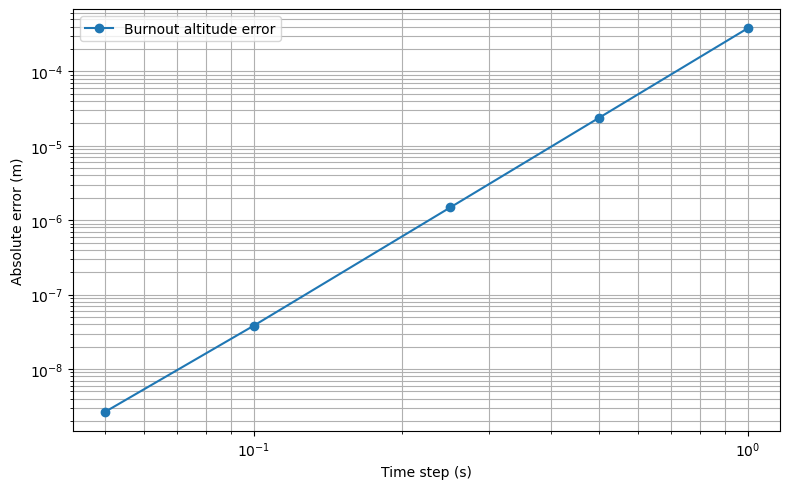

Time step (s) | Error (m)
       0.050 | 2.65390554e-09
       0.100 | 3.82242433e-08
       0.250 | 1.48667095e-06
       0.500 | 2.37800268e-05
       1.000 | 3.80047688e-04

Observed convergence orders:
0.05 to 0.10: 3.848
0.10 to 0.25: 3.995
0.25 to 0.50: 4.000
0.50 to 1.00: 3.998


In [2]:

import numpy as np
import matplotlib.pyplot as plt

# Parameters
m0 = 100.0
md = 40.0
T0 = 3000.0
mdot = 2.0
g0 = 9.81

tb = (m0 - md) / mdot

def exact_altitude(t):
    m = m0 - mdot*t
    return (
        T0/mdot**2 *
        (m0 - m - m*np.log(m0/m))
        - 0.5*g0*t**2
    )

def f(t, y):
    h, v = y
    m = m0 - mdot*t
    return np.array([v, T0/m - g0])

def rk4_step(t, y, dt):
    k1 = f(t, y)
    k2 = f(t+dt/2, y+dt*k1/2)
    k3 = f(t+dt/2, y+dt*k2/2)
    k4 = f(t+dt, y+dt*k3)
    return y + dt*(k1+2*k2+2*k3+k4)/6

def simulate(dt):
    t = 0.0
    y = np.array([0.0, 0.0])

    while t < tb - 1e-12:
        step = min(dt, tb-t)
        y = rk4_step(t, y, step)
        t += step

    return y[0]

steps = np.array([0.05, 0.1, 0.25, 0.5, 1.0])
errors = np.array([
    abs(simulate(dt) - exact_altitude(tb))
    for dt in steps
])

plt.figure(figsize=(8, 5))
plt.loglog(steps, errors, "o-",
           label="Burnout altitude error")
plt.xlabel("Time step (s)")
plt.ylabel("Absolute error (m)")
plt.grid(True, which="both")
plt.legend()
plt.tight_layout()

plt.savefig("rocket_convergence.pdf", bbox_inches="tight")
plt.show()

print("Time step (s) | Error (m)")
for dt, error in zip(steps, errors):
    print(f"{dt:12.3f} | {error:.8e}")

print("\nObserved convergence orders:")
for i in range(len(steps)-1):
    p = np.log(errors[i+1]/errors[i]) / \
        np.log(steps[i+1]/steps[i])
    print(f"{steps[i]:.2f} to {steps[i+1]:.2f}: {p:.3f}")


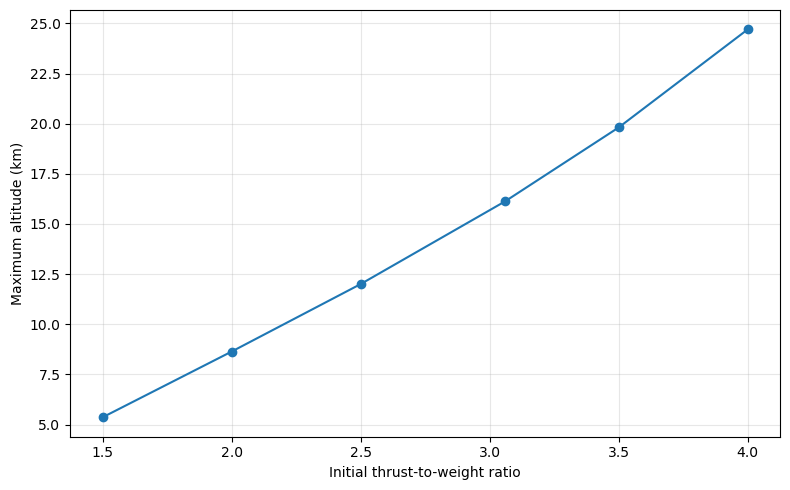

TWR = 1.50: altitude = 5.362 km
TWR = 2.00: altitude = 8.639 km
TWR = 2.50: altitude = 12.004 km
TWR = 3.06: altitude = 16.130 km
TWR = 3.50: altitude = 19.812 km
TWR = 4.00: altitude = 24.699 km


In [3]:

import numpy as np
import matplotlib.pyplot as plt

m0, md, mdot = 100.0, 40.0, 2.0
Cd, A = 0.5, 0.05
rho0, H = 1.225, 8500.0
g0, Re = 9.81, 6.371e6

tb = (m0-md)/mdot
dt = 0.05

def f(y, thrust, powered):
    h, v, m = y
    rho = rho0*np.exp(-max(h, 0)/H)
    g = g0*(Re/(Re+h))**2
    drag = 0.5*rho*Cd*A*v*abs(v)
    return np.array([
        v,
        ((thrust if powered else 0)-drag)/m-g,
        -mdot if powered else 0
    ])

def rk4(y, step, thrust, powered):
    k1 = f(y, thrust, powered)
    k2 = f(y+step*k1/2, thrust, powered)
    k3 = f(y+step*k2/2, thrust, powered)
    k4 = f(y+step*k3, thrust, powered)
    return y+step*(k1+2*k2+2*k3+k4)/6

def max_altitude(twr):
    thrust = twr*m0*g0
    y = np.array([0.0, 0.0, m0])
    t = 0.0

    while t < 200:
        powered = t < tb-1e-10
        step = min(dt, tb-t) if powered else dt
        old = y.copy()
        y = rk4(y, step, thrust, powered)
        t += step

        if not powered:
            y[2] = md

        if old[1] > 0 and y[1] <= 0:
            frac = old[1]/(old[1]-y[1])
            return (old[0]+frac*(y[0]-old[0]))/1000

    raise RuntimeError("Apogee not reached")

twr_values = np.array([1.5, 2.0, 2.5, 3.06, 3.5, 4.0])
altitudes = [max_altitude(x) for x in twr_values]

plt.figure(figsize=(8, 5))
plt.plot(twr_values, altitudes, "o-")
plt.xlabel("Initial thrust-to-weight ratio")
plt.ylabel("Maximum altitude (km)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("rocket_twr_study.pdf", bbox_inches="tight")
plt.show()

for x, h in zip(twr_values, altitudes):
    print(f"TWR = {x:.2f}: altitude = {h:.3f} km")


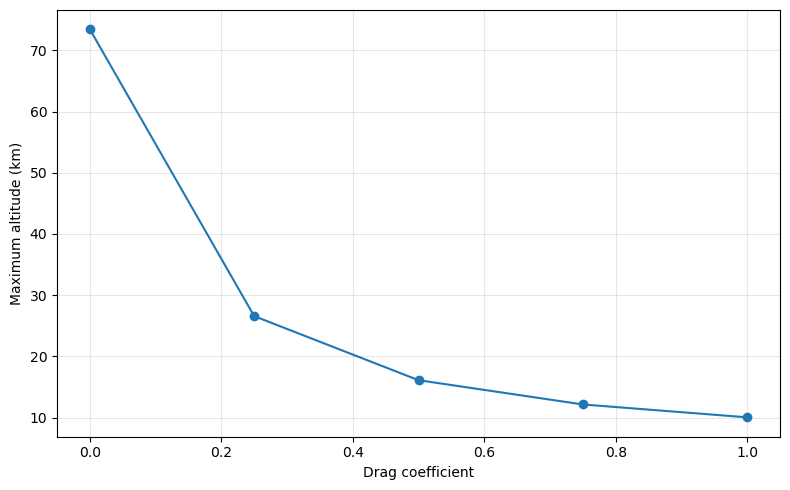

Drag coefficient | Maximum altitude (km)
            0.00 | 73.413
            0.25 | 26.576
            0.50 | 16.115
            0.75 | 12.149
            1.00 | 10.049


In [4]:

import numpy as np
import matplotlib.pyplot as plt

# Baseline parameters
m0, md = 100.0, 40.0
T0, mdot = 3000.0, 2.0
A = 0.05
rho0, H = 1.225, 8500.0
g0, Re = 9.81, 6.371e6

tb = (m0-md)/mdot
dt = 0.05

def f(y, Cd, powered):
    h, v, m = y
    rho = rho0*np.exp(-max(h, 0)/H)
    g = g0*(Re/(Re+h))**2
    drag = 0.5*rho*Cd*A*v*abs(v)

    return np.array([
        v,
        ((T0 if powered else 0)-drag)/m-g,
        -mdot if powered else 0
    ])

def rk4(y, step, Cd, powered):
    k1 = f(y, Cd, powered)
    k2 = f(y+step*k1/2, Cd, powered)
    k3 = f(y+step*k2/2, Cd, powered)
    k4 = f(y+step*k3, Cd, powered)
    return y+step*(k1+2*k2+2*k3+k4)/6

def max_altitude(Cd):
    t = 0.0
    y = np.array([0.0, 0.0, m0])

    while t < 300:
        powered = t < tb-1e-10
        step = min(dt, tb-t) if powered else dt
        old = y.copy()

        y = rk4(y, step, Cd, powered)
        t += step

        if not powered:
            y[2] = md

        if old[1] > 0 and y[1] <= 0:
            frac = old[1]/(old[1]-y[1])
            return (old[0]+frac*(y[0]-old[0]))/1000

    raise RuntimeError("Apogee not reached")

Cd_values = np.array([0.0, 0.25, 0.5, 0.75, 1.0])
altitudes = [max_altitude(Cd) for Cd in Cd_values]

plt.figure(figsize=(8, 5))
plt.plot(Cd_values, altitudes, "o-")
plt.xlabel("Drag coefficient")
plt.ylabel("Maximum altitude (km)")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("rocket_drag_study.pdf", bbox_inches="tight")
plt.show()

print("Drag coefficient | Maximum altitude (km)")
for Cd, h in zip(Cd_values, altitudes):
    print(f"{Cd:16.2f} | {h:.3f}")


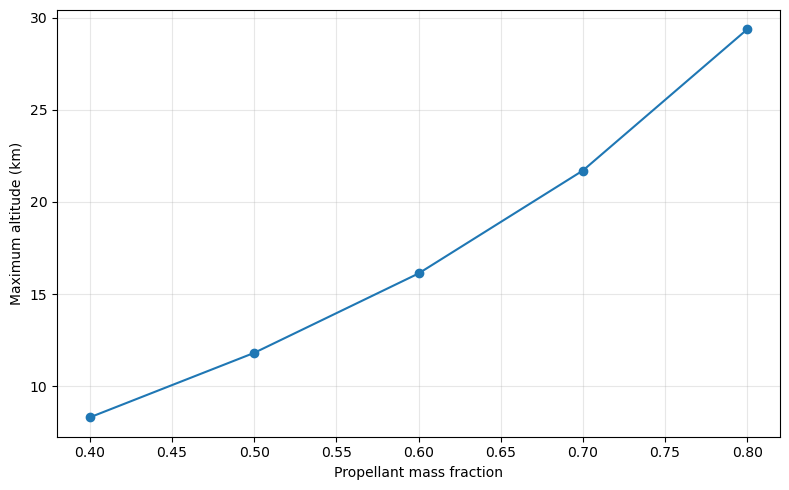

Propellant fraction | Maximum altitude (km)
              0.40 | 8.305
              0.50 | 11.805
              0.60 | 16.115
              0.70 | 21.702
              0.80 | 29.367


In [5]:

import numpy as np
import matplotlib.pyplot as plt

# Baseline parameters
m0 = 100.0
T0 = 3000.0
mdot = 2.0
Cd = 0.5
A = 0.05
rho0 = 1.225
H = 8500.0
g0 = 9.81
Re = 6.371e6

dt = 0.05

def f(y, powered):
    h, v, m = y
    rho = rho0*np.exp(-max(h, 0)/H)
    g = g0*(Re/(Re+h))**2
    drag = 0.5*rho*Cd*A*v*abs(v)

    return np.array([
        v,
        ((T0 if powered else 0)-drag)/m-g,
        -mdot if powered else 0
    ])

def rk4(y, step, powered):
    k1 = f(y, powered)
    k2 = f(y+step*k1/2, powered)
    k3 = f(y+step*k2/2, powered)
    k4 = f(y+step*k3, powered)
    return y+step*(k1+2*k2+2*k3+k4)/6

def max_altitude(fraction):
    md = m0*(1-fraction)
    tb = (m0-md)/mdot

    t = 0.0
    y = np.array([0.0, 0.0, m0])

    while t < 300:
        powered = t < tb-1e-10
        step = min(dt, tb-t) if powered else dt
        old = y.copy()

        y = rk4(y, step, powered)
        t += step

        if not powered:
            y[2] = md

        if old[1] > 0 and y[1] <= 0:
            frac = old[1]/(old[1]-y[1])
            return (old[0]+frac*(y[0]-old[0]))/1000

    raise RuntimeError("Apogee not reached")

fractions = np.array([0.4, 0.5, 0.6, 0.7, 0.8])
altitudes = [max_altitude(x) for x in fractions]

plt.figure(figsize=(8, 5))
plt.plot(fractions, altitudes, "o-")
plt.xlabel("Propellant mass fraction")
plt.ylabel("Maximum altitude (km)")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("rocket_mass_study.pdf", bbox_inches="tight")
plt.show()

print("Propellant fraction | Maximum altitude (km)")
for fraction, h in zip(fractions, altitudes):
    print(f"{fraction:18.2f} | {h:.3f}")
